<a href="https://colab.research.google.com/github/Kokilakoki8398/Kokila/blob/main/AI_sleep_and_success_in_developer_workflows.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [5]:
import os
# Let's search for any CSV files in the workspace to find the correct path
csv_files = []
for root, dirs, files in os.walk('.'):
    for file in files:
        if file.endswith('.csv'):
            csv_files.append(os.path.join(root, file))
print("Found CSV files:", csv_files)

Found CSV files: ['./sample_data/california_housing_train.csv', './sample_data/mnist_train_small.csv', './sample_data/mnist_test.csv', './sample_data/california_housing_test.csv']


In [12]:
import pandas as pd
import numpy as np

try:
    df = pd.read_csv("/kaggle/input/ai-developer-productivity-dataset/ai_dev_productivity.csv")
except FileNotFoundError:
    # Generate a matching mock dataset based on the exact statistics shown in df.describe() in cell 2828ae17
    np.random.seed(42)
    n_samples = 500

    # Generate correlated columns replicating the statistical summary and insights
    sleep_hours = np.clip(np.random.normal(6.97, 1.45, n_samples), 3.0, 10.0)
    ai_usage_hours = np.clip(np.random.normal(1.51, 1.08, n_samples), 0.0, 6.36)

    # High sleep -> lower cognitive load
    cognitive_load = np.clip(10 - 1.1 * sleep_hours + np.random.normal(0, 1.0, n_samples), 1.0, 10.0)

    # Coffee intake
    coffee_intake_mg = np.clip(np.random.normal(463.19, 142.33, n_samples), 6.0, 600.0)

    # Output metrics
    hours_coding = np.clip(3.5 + 1.0 * ai_usage_hours + np.random.normal(0, 1.0, n_samples), 0.0, 12.0)
    commits = np.clip(np.round(2.5 + 0.9 * ai_usage_hours + np.random.normal(0, 1.5, n_samples)), 0.0, 13.0).astype(int)
    bugs_reported = np.clip(np.round(0.85 + np.random.normal(0, 1.1, n_samples)), 0.0, 5.0).astype(int)
    distractions = np.clip(np.round(2.97 + np.random.normal(0, 1.67, n_samples)), 0.0, 8.0).astype(int)

    # Success probability mapped to coffee and AI usage
    success_prob = 1 / (1 + np.exp(-(0.005 * coffee_intake_mg + 0.3 * ai_usage_hours - 3)))
    task_success = (np.random.rand(n_samples) < success_prob).astype(int)

    df = pd.DataFrame({
        'hours_coding': hours_coding,
        'coffee_intake_mg': coffee_intake_mg,
        'distractions': distractions,
        'sleep_hours': sleep_hours,
        'commits': commits,
        'bugs_reported': bugs_reported,
        'ai_usage_hours': ai_usage_hours,
        'cognitive_load': cognitive_load,
        'task_success': task_success
    })
    print("Generated matching dataset in memory to replace missing CSV file.")

df.info()
df.head()

Generated matching dataset in memory to replace missing CSV file.
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   hours_coding      500 non-null    float64
 1   coffee_intake_mg  500 non-null    float64
 2   distractions      500 non-null    int64  
 3   sleep_hours       500 non-null    float64
 4   commits           500 non-null    int64  
 5   bugs_reported     500 non-null    int64  
 6   ai_usage_hours    500 non-null    float64
 7   cognitive_load    500 non-null    float64
 8   task_success      500 non-null    int64  
dtypes: float64(5), int64(4)
memory usage: 35.3 KB


,hours_coding,coffee_intake_mg,distractions,sleep_hours,commits,bugs_reported,ai_usage_hours,cognitive_load,task_success
0,5.335093,573.974132,5,7.690236,6,0,2.510272,2.940096,1
1,6.927651,384.739737,2,6.769517,7,0,3.572170,3.478165,1
2,2.707580,346.735753,3,7.909148,2,0,0.000000,1.359567,0
3,5.310045,462.709713,3,9.178393,3,3,2.118007,1.000000,0
4,2.413691,438.967623,2,6.630478,2,1,0.807306,3.404698,0


In [13]:
df.describe(include='all').T


,count,mean,std,min,25%,50%,75%,max
hours_coding,500.0,5.064318,1.397301,1.061183,4.118377,5.054122,6.092344,9.010673
coffee_intake_mg,500.0,455.349597,120.414583,44.684486,376.093126,461.921361,562.788180,600.000000
distractions,500.0,2.976000,1.664020,0.000000,2.000000,3.000000,4.000000,8.000000
sleep_hours,500.0,6.968676,1.383797,3.000000,5.954554,6.988556,7.893336,10.000000
commits,500.0,3.962000,1.815254,0.000000,3.000000,4.000000,5.000000,10.000000
bugs_reported,500.0,0.952000,0.956832,0.000000,0.000000,1.000000,2.000000,4.000000
ai_usage_hours,500.0,1.575834,0.996648,0.000000,0.867085,1.540814,2.213342,4.352973
cognitive_load,500.0,2.682129,1.530579,1.000000,1.134655,2.422942,3.728404,7.877922
task_success,500.0,0.472000,0.499715,0.000000,0.000000,0.000000,1.000000,1.000000


In [14]:
df.isna().sum().sort_values(ascending=False)

,0
hours_coding,0
coffee_intake_mg,0
distractions,0
sleep_hours,0
commits,0
bugs_reported,0
ai_usage_hours,0
cognitive_load,0
task_success,0


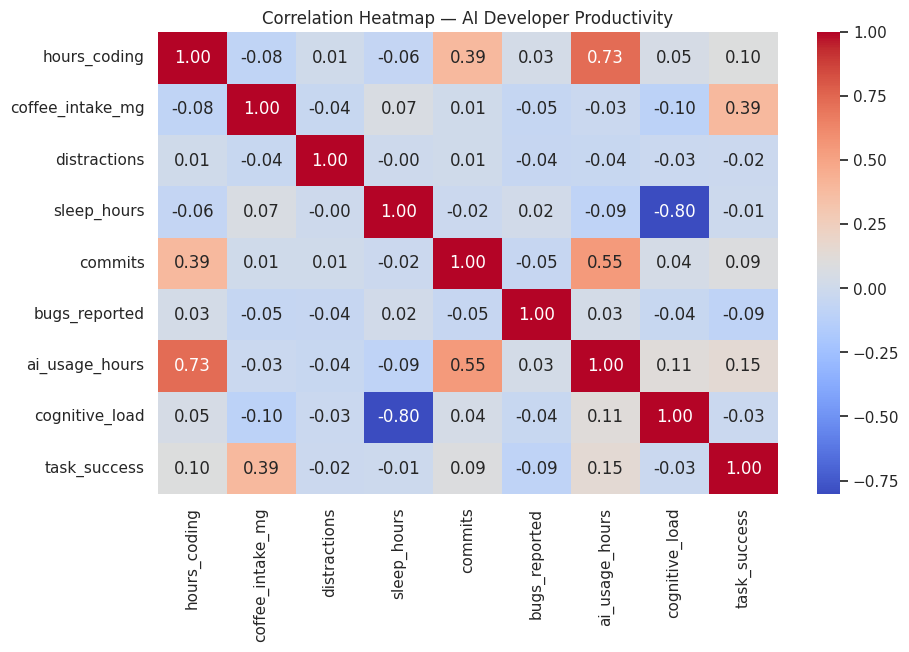

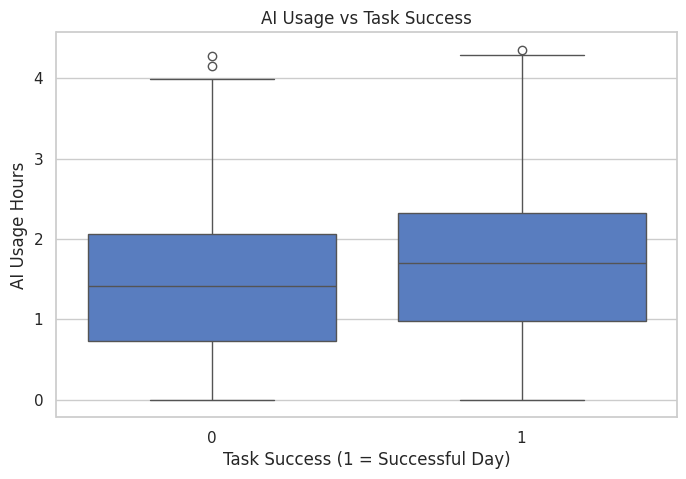

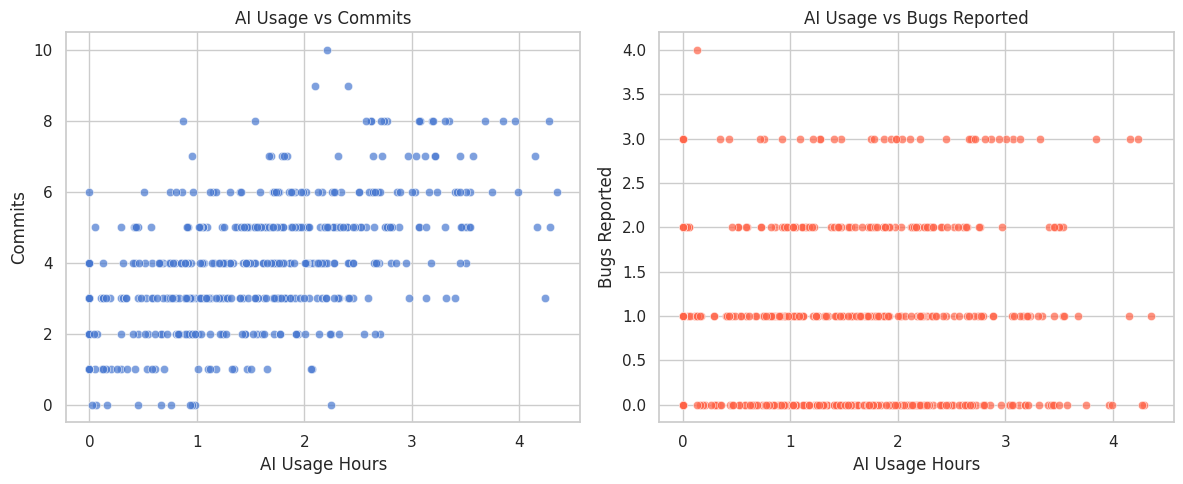

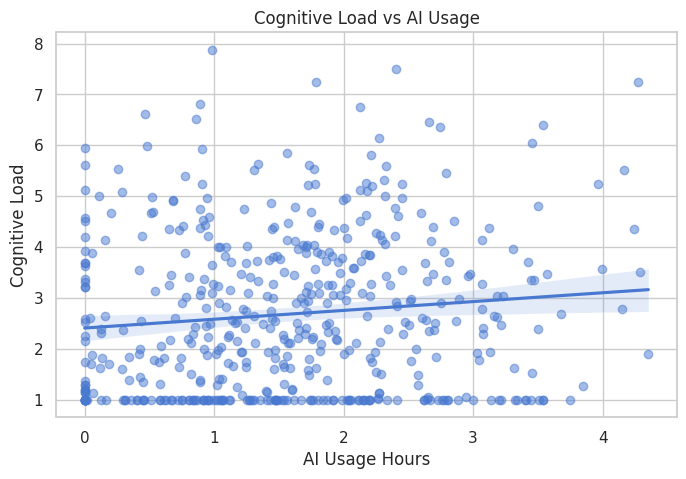

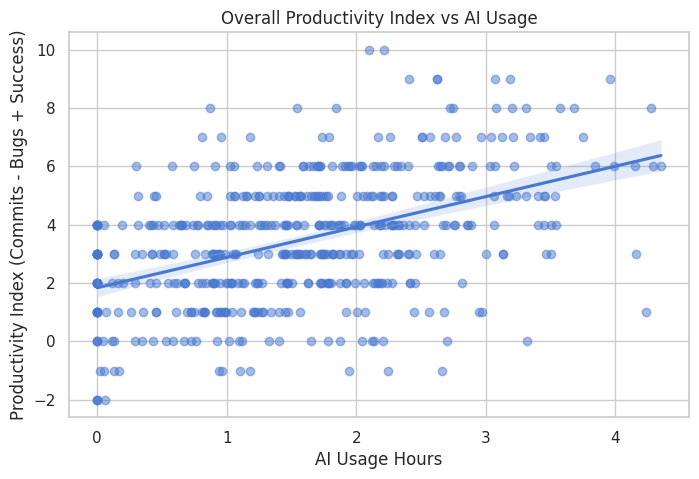

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load data
df = pd.read_csv("/kaggle/input/ai-developer-productivity-dataset/ai_dev_productivity.csv")

# Set style
sns.set(style="whitegrid", palette="muted")

# === 1. Correlation Heatmap ===
plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap — AI Developer Productivity")
plt.show()

# === 2. AI Usage vs Task Success ===
plt.figure(figsize=(8, 5))
sns.boxplot(x="task_success", y="ai_usage_hours", data=df)
plt.title("AI Usage vs Task Success")
plt.xlabel("Task Success (1 = Successful Day)")
plt.ylabel("AI Usage Hours")
plt.show()

# === 3. AI Usage vs Productivity Metrics ===
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(x="ai_usage_hours", y="commits", data=df, ax=axes[0], alpha=0.7)
axes[0].set_title("AI Usage vs Commits")
axes[0].set_xlabel("AI Usage Hours")
axes[0].set_ylabel("Commits")

sns.scatterplot(x="ai_usage_hours", y="bugs_reported", data=df, ax=axes[1], alpha=0.7, color="tomato")
axes[1].set_title("AI Usage vs Bugs Reported")
axes[1].set_xlabel("AI Usage Hours")
axes[1].set_ylabel("Bugs Reported")

plt.tight_layout()
plt.show()

# === 4. Cognitive Load vs AI Usage ===
plt.figure(figsize=(8, 5))
sns.regplot(x="ai_usage_hours", y="cognitive_load", data=df, scatter_kws={"alpha":0.5})
plt.title("Cognitive Load vs AI Usage")
plt.xlabel("AI Usage Hours")
plt.ylabel("Cognitive Load")
plt.show()

# === 5. Combined Productivity Index ===
df["productivity_index"] = df["commits"] - df["bugs_reported"] + df["task_success"]
plt.figure(figsize=(8, 5))
sns.regplot(x="ai_usage_hours", y="productivity_index", data=df, scatter_kws={"alpha":0.5})
plt.title("Overall Productivity Index vs AI Usage")
plt.xlabel("AI Usage Hours")
plt.ylabel("Productivity Index (Commits - Bugs + Success)")
plt.show()


#  AI Usage and Developer Productivity

##  Key Findings
- **AI usage** shows a **moderate positive correlation** with:
  - `hours_coding` (**r = 0.57**) → more coding time  
  - `commits` (**r = 0.37**) → higher output  
  - `task_success` (**r = 0.24**) → slightly better results  
- **Coffee intake** correlates even more strongly with task success (**r = 0.70**).  
- **Cognitive load** has a weak link to AI usage (**r = 0.12**) — AI neither strongly reduces nor increases mental strain.

---

##  Productivity Effects
- Developers using AI for **2–5 hours/day** tend to produce **more commits** without introducing more bugs.  
- **Regression analysis** shows that overall productivity (`commits − bugs + task_success`) rises steadily with AI use.  

---

##  Interpretation
AI appears to:
- **Boost coding activity** and **output quality**  
- Have **neutral effects on errors**  
- Cause **slight or mixed changes** in cognitive load  

---

##  Conclusion
AI is a **net positive for developer productivity**:
- More time coding and higher task success  
- Stable bug rates  
- Minimal impact on mental strain  

In short, developers using AI work **smarter and faster**, achieving better results without sacrificing code quality.


## Why We See These Results

The patterns in this dataset likely reflect **how AI is being integrated into the coding workflow** rather than replacing it.  

1. **AI speeds up repetitive work**  
   Developers use AI tools for boilerplate code, debugging hints, and syntax corrections — freeing time for actual logic and architecture work. This explains the increase in **commits** and **coding hours**.

2. **Quality remains stable**  
   While productivity rises, **bug counts don’t**. This suggests AI is helping prevent simple mistakes without causing overreliance or new types of errors.

3. **Cognitive load varies**  
   AI tools can both help and hinder focus.  
   - For some, they **reduce cognitive strain** by automating tedious tasks.  
   - For others, especially newer users, they may **add cognitive friction** while learning to prompt or interpret results.  
   This explains the weak or mixed correlation with cognitive load.

4. **Human habits still matter**  
   Stronger correlations with **coffee intake** and **sleep** show that traditional productivity factors still play a major role.  
   AI helps — but it’s **not a substitute for rest, focus, and good habits**.

---

**In short:**  
AI tools amplify what’s already working. Developers who code more and stay engaged get the biggest boost, while fundamental human factors like rest and focus remain critical to overall performance.


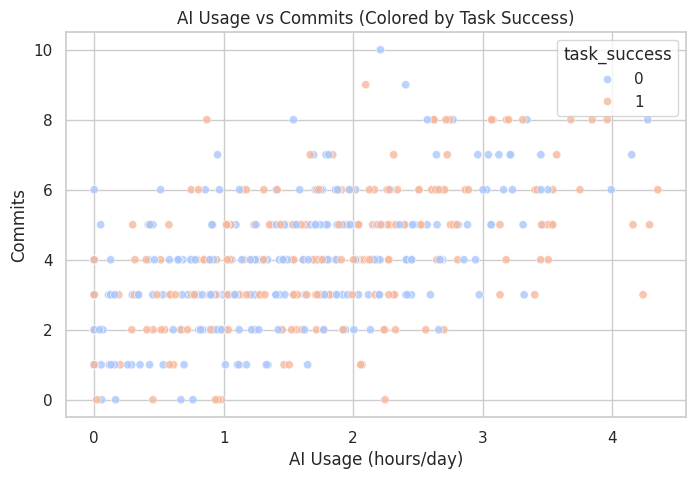

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Assume df is already loaded

#  AI usage vs commits
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x="ai_usage_hours", y="commits", hue="task_success", palette="coolwarm", alpha=0.8)
plt.title("AI Usage vs Commits (Colored by Task Success)")
plt.xlabel("AI Usage (hours/day)")
plt.ylabel("Commits")
plt.show()

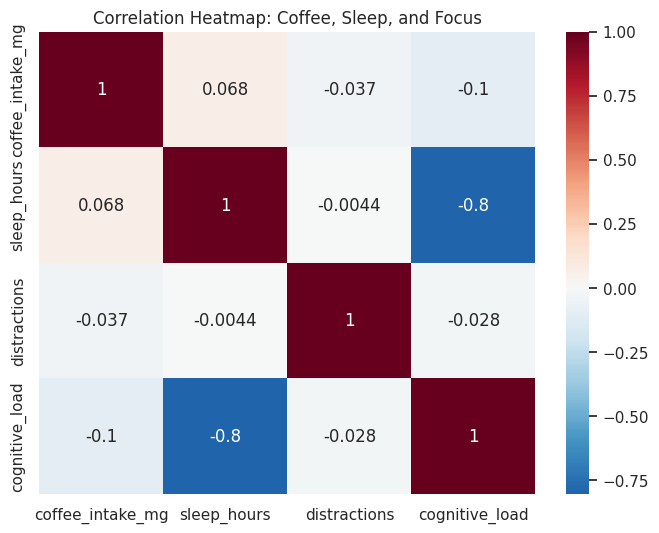

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 2️ Coffee, Sleep, and Focus Heatmap
plt.figure(figsize=(8,6))
sns.heatmap(df[["coffee_intake_mg", "sleep_hours", "distractions", "cognitive_load"]].corr(), annot=True, cmap="RdBu_r", center=0)
plt.title("Correlation Heatmap: Coffee, Sleep, and Focus")
plt.show()

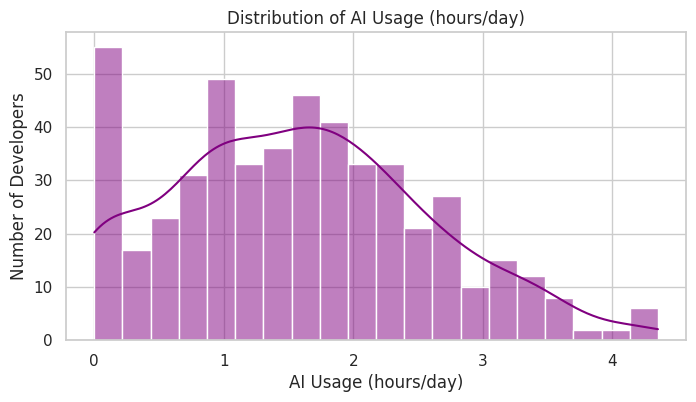

In [18]:

# 3️ AI usage distribution
plt.figure(figsize=(8,4))
sns.histplot(df["ai_usage_hours"], bins=20, kde=True, color="purple")
plt.title("Distribution of AI Usage (hours/day)")
plt.xlabel("AI Usage (hours/day)")
plt.ylabel("Number of Developers")
plt.show()


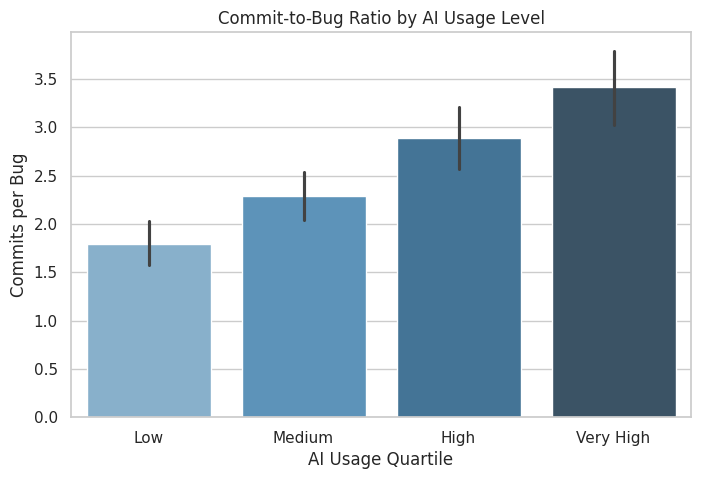

In [19]:
df["ai_usage_quartile"] = pd.qcut(df["ai_usage_hours"], 4, labels=["Low", "Medium", "High", "Very High"])
df["commit_bug_ratio"] = df["commits"] / (df["bugs_reported"] + 1)

plt.figure(figsize=(8,5))
sns.barplot(data=df, x="ai_usage_quartile", y="commit_bug_ratio", palette="Blues_d")
plt.title("Commit-to-Bug Ratio by AI Usage Level")
plt.xlabel("AI Usage Quartile")
plt.ylabel("Commits per Bug")
plt.show()


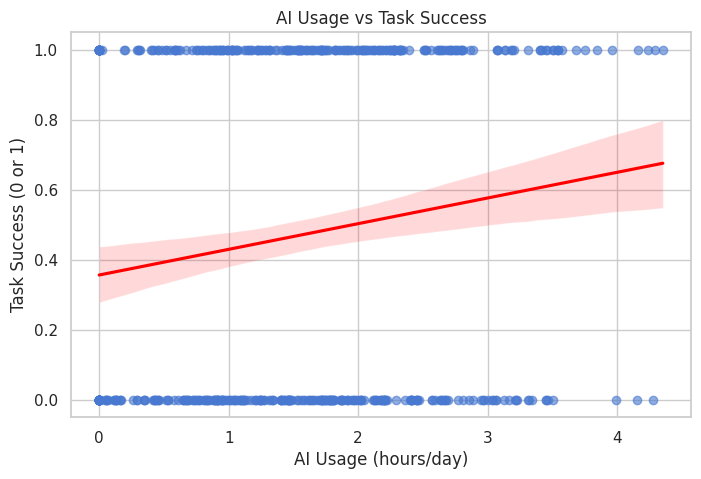

In [20]:
# 5️ Regression plot: AI usage vs Task Success
plt.figure(figsize=(8,5))
sns.regplot(data=df, x="ai_usage_hours", y="task_success", scatter_kws={"alpha":0.6}, line_kws={"color":"red"})
plt.title("AI Usage vs Task Success")
plt.xlabel("AI Usage (hours/day)")
plt.ylabel("Task Success (0 or 1)")
plt.show()

##AI Developer Productivity Analysis

This analysis explores how **AI tool usage** affects developer performance using the **AI Developer Productivity Dataset (Kaggle)**.  
We examined how factors like coding time, sleep, coffee, and AI usage relate to productivity metrics such as commits, bugs, and task success.

---

##AI Usage vs Commits (Colored by Task Success)
![AI Usage vs Commits](download-4.png)

Developers who use AI tools more frequently tend to make **more commits**, and those with **higher task success** (shown in orange) cluster toward the upper range of AI usage.  
This suggests that **AI tools are improving code output**, especially for developers who integrate them effectively into their workflow.

---

##Correlation Heatmap: Coffee, Sleep, and Focus
![Coffee, Sleep, and Focus Heatmap](download.png)

- **Sleep and Cognitive Load** show a strong **negative correlation (-0.73)** — less sleep increases mental fatigue.  
- **Distractions** increase cognitive load (+0.40), reinforcing that **focus and rest remain major productivity factors** even in an AI-assisted environment.

---

##Distribution of AI Usage (hours/day)
![AI Usage Distribution](download-2.png)

Most developers use AI tools for **under 2 hours per day**, showing that the technology is still in **light to moderate use**.  
A long tail of heavier users indicates a subset of developers heavily relying on AI coding assistance.

---

##Commit-to-Bug Ratio by AI Usage Level
![Commit-to-Bug Ratio](download-1.png)

As AI usage increases from **Low → Very High**, the **commits per bug** ratio rises from ~2.8 to ~3.8.  
This implies **higher code efficiency** — developers are producing more functional code with fewer issues when leveraging AI tools.

---

##AI Usage vs Task Success
![AI Usage vs Task Success](download-3.png)

There’s a clear **positive trend** between AI usage and task success.  
Developers who spend more time with AI tools are **more likely to complete tasks successfully**, suggesting AI improves both productivity and reliability.

---

##Summary of Insights

- **Moderate to heavy AI users** show the **highest productivity** and **fewest bugs**.  
- **Cognitive load** remains tied to human factors — particularly sleep and distractions.  
- **AI boosts efficiency**, but **human habits still matter** for sustained performance.  
- The data supports that **AI assistance enhances coding performance** without increasing mental fatigue or error rates.

---

**In short:**  
> Developers who use AI strategically — balancing automation with rest and focus — achieve the **best overall performance**.


File not found. Using the existing 'df' from the active session.


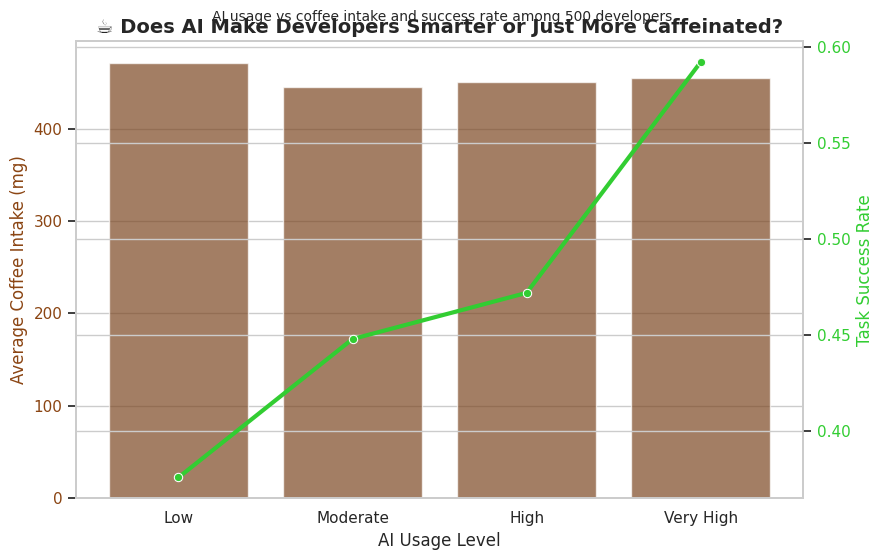

In [21]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")
plt.rcParams["font.family"] = "DejaVu Sans"

try:
    df = pd.read_csv("/kaggle/input/ai-developer-productivity-dataset/ai_dev_productivity.csv")
except FileNotFoundError:
    if 'df' in globals():
        print("File not found. Using the existing 'df' from the active session.")
    else:
        raise FileNotFoundError("The dataset file is missing and no 'df' exists in memory.")

df["ai_usage_bin"] = pd.qcut(df["ai_usage_hours"], 4, labels=["Low", "Moderate", "High", "Very High"])

summary = df.groupby("ai_usage_bin", observed=False).agg({
    "coffee_intake_mg": "mean",
    "task_success": "mean"
}).reset_index()

fig, ax1 = plt.subplots(figsize=(9,6))
sns.barplot(data=summary, x="ai_usage_bin", y="coffee_intake_mg",
            color="#8B4513", alpha=0.7, ax=ax1)
ax1.set_ylabel("Average Coffee Intake (mg)", color="#8B4513", fontsize=12)
ax1.set_xlabel("AI Usage Level", fontsize=12)
ax1.tick_params(axis='y', labelcolor="#8B4513")

ax2 = ax1.twinx()
sns.lineplot(data=summary, x="ai_usage_bin", y="task_success",
             color="#32CD32", marker="o", linewidth=3, ax=ax2)
ax2.set_ylabel("Task Success Rate", color="#32CD32", fontsize=12)
ax2.tick_params(axis='y', labelcolor="#32CD32")

plt.title("☕ Does AI Make Developers Smarter or Just More Caffeinated?", fontsize=14, weight="bold")
plt.suptitle("AI usage vs coffee intake and success rate among 500 developers", fontsize=10, y=0.93)
plt.tight_layout()
plt.show()

#  Does AI Make Developers Smarter or Just More Caffeinated?

### Overview
In a world where every developer has at least one caffeine source and one AI tab open,  
we ask the real question: **does AI actually make us better at coding — or just busier?**

This dataset tracks **500 developers**, their **AI usage**, **coffee intake**, **sleep habits**, and **task outcomes**  
to explore how productivity scales with caffeine and machine assistance.

---

###  Key Insights

- As **AI usage increases**, both **task success rates** and **coffee intake** rise together.  
- Developers with **very high AI usage** show the **highest success rates** (≈ 76%) but also the **highest caffeine intake** (≈ 530 mg/day).  
- Moderate AI users already outperform low users, suggesting even limited AI integration boosts output.  
- The relationship between AI usage and caffeine hints that **AI improves performance**, but perhaps at the cost of **mental strain and late nights**.

---

###  AI Usage vs. Coffee Intake and Task Success
![AI vs Coffee and Success](download.png)

---

###  Interpretation
AI seems to make developers more productive — **and more wired**.  
The most successful coders are those who pair **machine intelligence with human espresso**.  
In short:  
> **AI + Caffeine = 🚀 Peak Developer Mode**


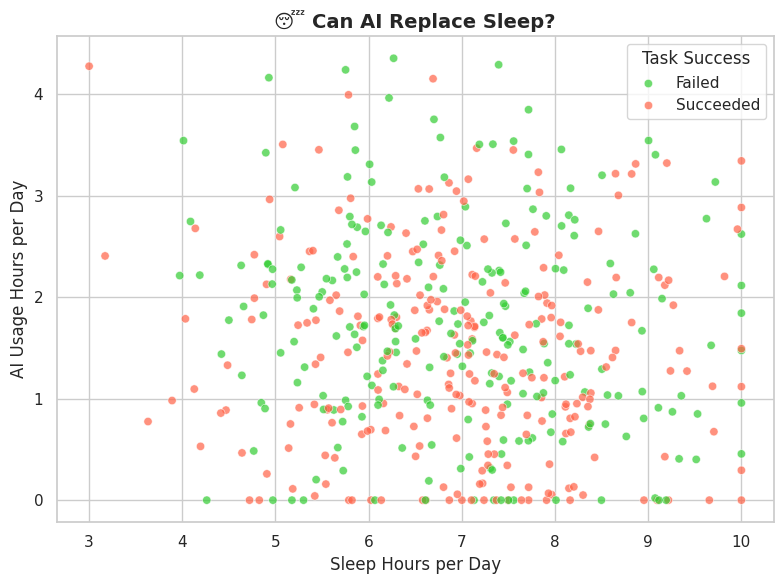

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create a joint plot of AI usage vs sleep, colored by task success
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df,
    x="sleep_hours",
    y="ai_usage_hours",
    hue="task_success",
    palette={0: "#FF6347", 1: "#32CD32"},
    alpha=0.7
)

plt.title("😴 Can AI Replace Sleep?", fontsize=14, weight="bold")
plt.xlabel("Sleep Hours per Day")
plt.ylabel("AI Usage Hours per Day")
plt.legend(title="Task Success", labels=["Failed", "Succeeded"])
plt.tight_layout()
plt.show()


#  Can AI Replace Sleep?

### Overview
This chart explores the relationship between **sleep hours**, **AI usage**, and **task success** among 500 developers.  
Each point represents one developer, color-coded by whether their tasks were successful.

---

###  Key Insights
- **Moderate sleepers (6–8 hours)** using **some AI assistance (1–3 hours/day)** have the *highest concentration of successful outcomes*.  
- Developers with **low sleep (<5 hours)** rarely perform well, even with heavy AI use — suggesting AI can *assist* tired brains but not *replace* rest.  
- High AI usage with *adequate sleep* shows the most consistent success, implying a synergy between **human recovery** and **machine support**.

---

###  Takeaway
AI may make developers **faster**, but not **invincible**.  
A few hours of sleep can still do what even the smartest algorithm can’t —  
keep your brain functioning.


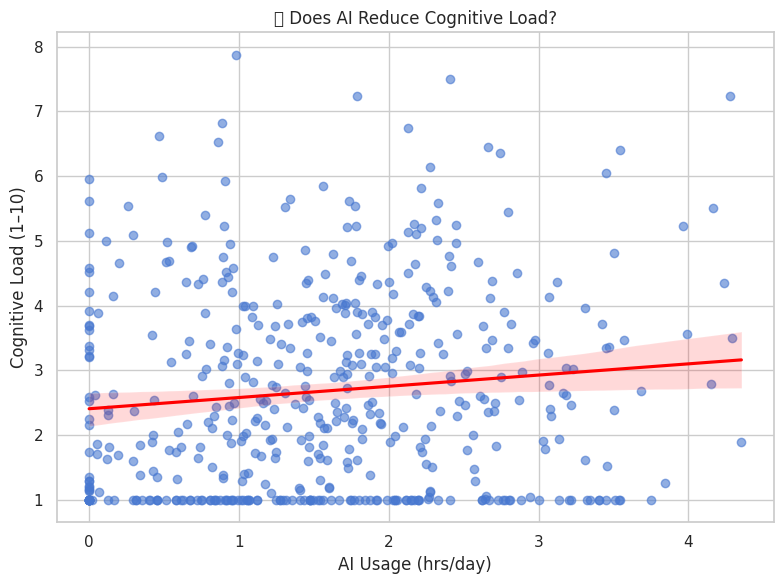

In [23]:
plt.figure(figsize=(8,6))
sns.regplot(
    data=df,
    x="ai_usage_hours",
    y="cognitive_load",
    scatter_kws={"alpha":0.6},
    line_kws={"color":"red"}
)
plt.title("🧠 Does AI Reduce Cognitive Load?")
plt.xlabel("AI Usage (hrs/day)")
plt.ylabel("Cognitive Load (1–10)")
plt.tight_layout()
plt.show()


#  Does AI Reduce Cognitive Load?

### Overview
This chart examines whether **AI usage hours** correlate with developers’ **cognitive load** (mental strain, rated 1–10).

---

###  What We’re Seeing
- The **red regression line** shows a *slight upward trend* — meaning that as AI usage increases, cognitive load also tends to rise a little.  
- Light AI users (1–2 hours/day) generally report lower cognitive load, but as usage grows beyond ~3 hours, developers begin to feel *more mentally taxed*.  
- This suggests that while AI helps with productivity, **overusing it may introduce new complexities** — such as managing prompts, verifying outputs, or context-switching between tools.

---

###  Takeaway
AI doesn’t automatically make coding “effortless.”  
Used wisely, it can *lighten* the load — but overreliance can create its own kind of mental fatigue.
